# Simulation result explorer

In [1]:
import sys
from pathlib import Path

import ipywidgets as widgets
import matplotlib.pyplot as plt
import numpy as np
import scienceplots  # noqa: F401
from IPython.display import display
from matplotlib.cm import ScalarMappable
from matplotlib.colors import Normalize
from matplotlib.ticker import MaxNLocator
from matplotlib_inline.backend_inline import set_matplotlib_formats

%matplotlib inline
plt.style.use("science")
set_matplotlib_formats("svg")
extra = 3
plt.rcParams.update({
    "font.size": 14+extra,
    "axes.titlesize": 17+extra,
    "axes.labelsize": 15+extra,
    "xtick.labelsize": 12+extra,
    "ytick.labelsize": 12+extra,
    "legend.fontsize": 12+extra,
    "legend.title_fontsize": 13+extra,
    "figure.titlesize": 19+extra,
})

project_root = next(
    (
        path
        for path in (Path.cwd().resolve(), *Path.cwd().resolve().parents)
        if (path / "pyproject.toml").is_file() and (path / "tasks").is_dir()
    ),
    None,
)
if project_root is None:
    raise RuntimeError("Run this notebook from the network-creation repository.")
if str(project_root) not in sys.path:
    sys.path.insert(0, str(project_root))

from network_creation.plotting.plot_pair import plot_pair
from network_creation.plotting.reference_values import get_observer_reference_style
from tasks.policies import load_policy_results

In [32]:
CONFIG = {
    "result_store": (
        project_root
        / "artifacts"
        / "simulation_runs"
        / "run-20260809T143129.zarr"
    ),
    "normalize_time": True,
    "export": {
        "output_root": project_root / "artifacts" / "figures",
        "dpi": 300,
    },
    "observables": {
        "centered_mean_welfare.mean": {
            "label": "Mean terminal welfare",
            "limits": (0.0, 1.0),
        },
        "hub_sponsorship.mean": {
            "label": "Mean terminal hub sponsorship",
            "limits": (0.0, 1.0),
        },
        "centered_mean_welfare.std": {
            "label": "SD of terminal welfare",
            "limits": (0.0, None),
            "scale_per_n_agents": False,  # False uses one global scale.
        },
    },
    "plot": {
        "method": "gaussian",
        "cmap": "jet",
        "resolution": 50,
        "point_size": 4,
        "pair_atol": 1e-5,
        "figure_side": 4,
        "subplot_spacing": 0.06,
        "subplot_margins": {
            "left": 0.125,
            "right": 0.895,
            "bottom": 0.11,
            "top": 0.88,
        },
        "colorbar_bounds": (0.2, 0.0, 0.08, 1.0),
        "single_colorbar_bounds": (1.08, 0.0, 0.05, 1.0),
        "reference_label_spacing": 0.07,
        "parameter_labels": {
            "visibility_distance": "Visibility radius",
            "exploration": "Decision temperature",
            "outside_optimism": "Unseen-spillover weight",
        },
        "reference_labels": {
            "star": "Star",
            "random": "Max ER",
            "choi2020": "Choi_2020",
            "empty": "Empty",
            "center_sponsored_star": "CSS",
            "periphery_sponsored_star": "PSS",
        },
        "show_choi2020_reference": True,
    },
}

In [33]:
results = load_policy_results(
    CONFIG["result_store"],
    stats=tuple(CONFIG["observables"]),
    normalize_time=CONFIG["normalize_time"],
)
last_step = results["x"].isel(step=-1, drop=True).rename("last_step")

composition_dims = tuple(
    dim
    for dim in results["x"].dims
    if dim not in {"n_agents", "parameter_row", "step", "observable"}
)
if len(composition_dims) != 1:
    raise ValueError(
        f"Expected one policy-composition dimension, found {composition_dims}."
    )
composition_dim = composition_dims[0]

loaded_path = Path(results.attrs["result_store_path"])
print(f"Loaded {loaded_path.relative_to(project_root)}")
print(f"Has failures: {results.attrs['has_failures']}")
print(f"Last shared step: {float(results.coords['step'][-1]):g}")
print(f"Time axis: {results.attrs.get('time_axis', 'raw_simulator_steps')}")

Loaded artifacts/simulation_runs/run-20260809T143129.zarr
Has failures: False
Last shared step: 60
Time axis: activation_opportunities_per_agent


In [34]:
def resolve_norm(observable, values, references):
    finite = np.asarray(values, dtype=float).ravel()
    finite = finite[np.isfinite(finite)]
    if references:
        finite = np.concatenate([finite, np.asarray(list(references.values()))])
    if not finite.size:
        raise ValueError(f"No finite values are available for {observable!r}.")

    configured_min, configured_max = CONFIG["observables"][observable]["limits"]
    vmin = float(finite.min()) if configured_min is None else float(configured_min)
    vmax = float(finite.max()) if configured_max is None else float(configured_max)
    return Normalize(vmin=vmin, vmax=vmax)


def spread_reference_label_positions(positions, lower, upper, min_spacing):
    positions = np.asarray(positions, dtype=float).copy()
    if positions.size < 2:
        return positions

    min_spacing = min(
        float(min_spacing), (upper - lower) / (positions.size - 1)
    )
    for _ in range(256):
        previous = positions.copy()
        for index in range(positions.size - 1):
            overlap = min_spacing - (positions[index + 1] - positions[index])
            if overlap > 0.0:
                positions[index] -= overlap / 2.0
                positions[index + 1] += overlap / 2.0
        positions = np.clip(positions, lower, upper)
        if np.max(np.abs(positions - previous)) < 1e-9:
            break
    return positions


def group_close_reference_positions(positions, threshold):
    if not positions:
        return []

    groups = [[0]]
    for index in range(1, len(positions)):
        if positions[index] - positions[index - 1] < threshold:
            groups[-1].append(index)
        else:
            groups.append([index])
    return groups


def draw_color_scale(axis, norm, cmap, references, label, has_under_range):
    colorbar = axis.figure.colorbar(
        ScalarMappable(norm=norm, cmap=cmap),
        cax=axis,
        extend="min" if has_under_range else "neither",
    )

    visible_references = {
        name: value
        for name, value in references.items()
        if name != "choi2020"
        or CONFIG["plot"]["show_choi2020_reference"]
    }
    if visible_references:
        items = sorted(visible_references.items(), key=lambda item: item[1])
        tick_values = [value for _, value in items]
        tick_labels = [
            f"{CONFIG['plot']['reference_labels'].get(name, name)} ({value:.2f})"
            for name, value in items
        ]
        tick_positions = [float(norm(value)) for value in tick_values]
        label_positions = spread_reference_label_positions(
            tick_positions,
            0.0,
            1.0,
            CONFIG["plot"]["reference_label_spacing"],
        )
        label_groups = group_close_reference_positions(
            tick_positions, CONFIG["plot"]["reference_label_spacing"]
        )
    else:
        tick_values = MaxNLocator(nbins=6).tick_values(norm.vmin, norm.vmax)
        tick_values = [
            value for value in tick_values if norm.vmin <= value <= norm.vmax
        ]
        tick_labels = [f"{value:.2f}" for value in tick_values]
        tick_positions = [float(norm(value)) for value in tick_values]

    axis.set_yticks(
        tick_values,
        labels=[""] * len(tick_positions) if visible_references else tick_labels,
    )
    axis.minorticks_off()
    axis.yaxis.tick_right()
    axis.yaxis.set_label_position("left")
    colorbar.set_label(label)
    if visible_references:
        label_transform = axis.transAxes
        rail_x = 1.22
        line_end_x = 1.32
        text_x = 1.45
        line_style = {
            "color": "black",
            "linewidth": 0.8,
            "solid_capstyle": "butt",
            "clip_on": False,
            "transform": label_transform,
        }
        for group in label_groups:
            group_ticks = [tick_positions[index] for index in group]
            group_labels = [label_positions[index] for index in group]
            for tick_position in group_ticks:
                axis.plot([1.0, rail_x], [tick_position, tick_position], **line_style)
            axis.plot(
                [rail_x, rail_x],
                [min(*group_ticks, *group_labels), max(*group_ticks, *group_labels)],
                **line_style,
            )
            for label_position in group_labels:
                axis.plot(
                    [rail_x, line_end_x],
                    [label_position, label_position],
                    **line_style,
                )
        for label_position, tick_label in zip(
            label_positions, tick_labels, strict=True
        ):
            axis.text(
                text_x,
                label_position,
                tick_label,
                transform=label_transform,
                ha="left",
                va="center",
                fontsize=plt.rcParams["ytick.labelsize"],
                clip_on=False,
            )
    colorbar.outline.set_edgecolor("black")
    colorbar.outline.set_linewidth(1.0)


def plot_last_step(observable, n_agents, composition):
    selector = {
        "observable": observable,
        "n_agents": n_agents,
        composition_dim: composition,
    }
    values = last_step.sel(selector)
    theta = results["theta"].sel(
        n_agents=n_agents,
        **{composition_dim: composition},
    )
    valid = values.notnull() & theta.notnull().all("theta_parameter")
    values = values.where(valid, drop=True)
    theta = theta.where(valid, drop=True)
    if not values.sizes.get("parameter_row", 0):
        raise ValueError("No finite final values match this selection.")

    plot_config = CONFIG["plot"]
    varying_parameters = int(
        (theta.var("parameter_row") > plot_config["pair_atol"]).sum().item()
    )
    n_axes = varying_parameters - 1
    if n_axes < 1:
        raise ValueError("At least two sampled parameters must vary for a pair plot.")

    theta_names = [str(name) for name in theta.coords["theta_parameter"].values]
    parameter_labels = plot_config["parameter_labels"]
    labels = [parameter_labels.get(name, name) for name in theta_names]

    references = {}
    if observable.split(".")[1:2] == ["mean"]:
        references, _ = get_observer_reference_style(
            observable,
            values.to_numpy(),
            n_agents=int(n_agents),
            theta_labels=theta_names,
            theta_values=theta.to_numpy(),
        )

    scale_selector = {"observable": observable}
    if CONFIG["observables"][observable].get("scale_per_n_agents", False):
        scale_selector["n_agents"] = n_agents
    shared_values = last_step.sel(scale_selector).to_numpy()
    norm = resolve_norm(observable, shared_values, references)
    base_cmap = plt.get_cmap(plot_config["cmap"])
    cmap = base_cmap.with_extremes(under=base_cmap(0.0))
    has_under_range = bool(
        norm.vmin is not None
        and np.any(np.isfinite(shared_values) & (shared_values < norm.vmin))
    )

    with plt.ioff():
        fig, axes = plt.subplots(
            n_axes,
            n_axes,
            squeeze=False,
            figsize=(plot_config["figure_side"] * n_axes,) * 2,
            gridspec_kw={
                "wspace": plot_config["subplot_spacing"],
                "hspace": plot_config["subplot_spacing"],
            },
        )
        fig.subplots_adjust(**plot_config["subplot_margins"])
    plot_pair(
        X=theta.to_numpy(),
        y=values.to_numpy(),
        labels=labels,
        ordered_discrete_keys=[
            parameter_labels.get("visibility_distance", "visibility_distance")
        ]
        if "visibility_distance" in theta_names
        else [],
        atol=plot_config["pair_atol"],
        cmap=cmap,
        method=plot_config["method"],
        resolution=plot_config["resolution"],
        point_size=plot_config["point_size"],
        norm=norm,
        fig=fig,
        axes=axes,
    )

    if n_axes == 1:
        colorbar_axis = axes[0, 0].inset_axes(
            plot_config["single_colorbar_bounds"]
        )
    else:
        colorbar_slot = axes[0, -1]
        colorbar_slot.clear()
        colorbar_slot.axis("off")
        colorbar_axis = colorbar_slot.inset_axes(plot_config["colorbar_bounds"])
    draw_color_scale(
        colorbar_axis,
        norm,
        cmap,
        references,
        CONFIG["observables"][observable]["label"],
        has_under_range,
    )
    fig.align_ylabels(axes[:, 0])

    composition_label = composition_dim.replace("_", " ")
    """
    fig.suptitle(
        f"{CONFIG['observables'][observable]['label']}\n"
        f"n_agents={int(n_agents)}, {composition_label}={composition:g}"
    )
    """
    return fig

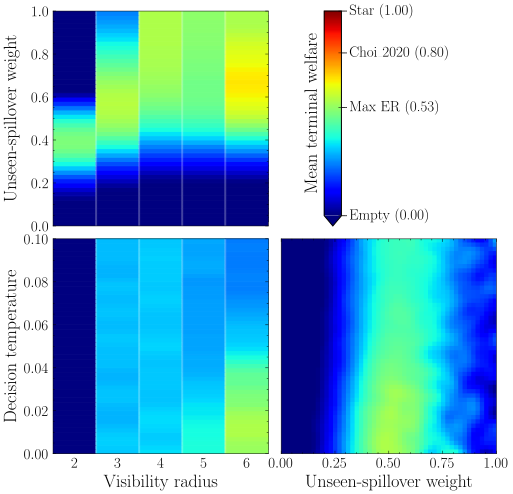

In [ ]:
control_style = {"description_width": "initial"}
controls = {
    "observable": widgets.Dropdown(
        description="Observer",
        options=[
            (metadata["label"], observable)
            for observable, metadata in CONFIG["observables"].items()
        ],
        style=control_style,
        layout=widgets.Layout(width="320px"),
    ),
    "n_agents": widgets.Dropdown(
        description="n agents",
        options=[int(value) for value in results.coords["n_agents"].values],
        style=control_style,
    ),
    "composition": widgets.Dropdown(
        description=composition_dim.replace("_", " "),
        options=[
            (f"{value:g}", value)
            for value in results.coords[composition_dim].values.tolist()
        ],
        style=control_style,
    ),
}

plot_controls = widgets.HBox(
    list(controls.values()),
    layout=widgets.Layout(
        gap="12px",
        align_items="flex-start",
        flex_flow="row wrap",
    ),
)


def build_plot():
    figure = plot_last_step(
        controls["observable"].value,
        controls["n_agents"].value,
        controls["composition"].value,
    )
    plt.close(figure)
    return figure


def update_plot(_):
    try:
        plot_display.update(build_plot())
    except ValueError as error:
        plot_display.update(str(error))


display(plot_controls)
plot_display = display(build_plot(), display_id=True)
for control in controls.values():
    control.observe(update_plot, names="value")

In [36]:
run_id = Path(CONFIG["result_store"]).stem
figure_dir = CONFIG["export"]["output_root"] / run_id
figure_dir.mkdir(parents=True, exist_ok=True)

pdf_paths = []
for observable in CONFIG["observables"]:
    for n_agents in results.coords["n_agents"].values:
        for composition in results.coords[composition_dim].values:
            figure = plot_last_step(
                observable, int(n_agents), composition.item()
            )
            filename = (
                f"{observable}__n_agents-{int(n_agents)}__"
                f"{composition_dim}-{composition:g}__{CONFIG['plot']['method']}.pdf"
            )
            pdf_path = figure_dir / filename
            figure.savefig(
                pdf_path,
                format="pdf",
                dpi=CONFIG["export"]["dpi"],
                bbox_inches="tight",
            )
            plt.close(figure)
            pdf_paths.append(pdf_path)

print(
    f"Saved {len(pdf_paths)} PDFs to "
    f"{figure_dir.relative_to(project_root)}"
)

Saved 9 PDFs to artifacts/figures/run-20260809T143129
